# 15 · 评估是否可信，下一次该改哪里
## 目标
手算官方指标，核对两市场的正确加权方式，查看主实验的固定审计结果和误差案例。
**公开 audit 后，这批数据已成为可见基准。继续反复优化它，就不能再声称它是未触碰的测试集。**
## 准备
[官方协议](https://xmrec.github.io/wsdmcup/) · [冠军论文](https://arxiv.org/abs/2203.00897) · [指标实现](../reclab/competition/metrics.py)。

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd()
if not (ROOT / "reclab").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code
from reclab.competition import data
from reclab.competition.teaching import load_run, style, bar_scores
style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
run, rows, features = load_run()
print("实际训练快照:", run.name)

实际训练快照: 20261030T115556803593-cloud-restore


## 步骤 1 · 一个正例的 nDCG
正例在第 r 名且 r≤10 时为 `1/log2(r+1)`，否则为 0。所有用户取平均。
官方合并 t1、t2 的用户后平均，因此不能简单把两个市场分数相加除以 2。

In [2]:
from reclab.competition.metrics import evaluate, per_user
display(pd.DataFrame({"positive_rank": [1,2,3,10,11], "ndcg10": [1/np.log2(r+1) if r <=10 else 0 for r in [1,2,3,10,11]]}))
predictions = pd.read_parquet(run / "valid_predictions.parquet")
selection = json.loads((run / "selection.json").read_text())
chosen = selection["selected"]
audit = rows.partition.eq("audit").to_numpy()
report = evaluate(rows.loc[audit], predictions.loc[audit, chosen])
display(report)
by_market = report[report.market.ne("combined")]
weighted = np.average(by_market.ndcg10, weights=by_market.users)
assert np.isclose(weighted, report.iloc[-1].ndcg10)
print("仅按 select 冻结的主模型:", chosen)

,positive_rank,ndcg10
0,1,1.000000
1,2,0.630930
2,3,0.500000
3,10,0.289065
4,11,0.000000


,market,users,ndcg10,hr10
0,t1,543,0.711020,0.799263
1,t2,1062,0.615750,0.718456
2,combined,1605,0.647982,0.745794


仅按 select 冻结的主模型: lgb_memory


## 步骤 2 · 所有对照用同一批 audit 用户
`lgb_stats` 只有统计特征；`lgb_memory` 增加协同过滤；`lgb_all` 再加小图模型；`lgb_neg9` 只减少训练负例。
全部配置在查看 audit 前固定。原冠军隐藏测试 0.6773 与本地 audit 不同，不画成同一条排行榜。

,model,users,ndcg10,hr10
86,lgb_memory,1605,0.647982,0.745794
95,lgb_all,1605,0.647218,0.744548
104,lgb_neg9,1605,0.646032,0.743925
50,icf_all_rating,1605,0.628597,0.720249
41,icf_all_iuf,1605,0.626545,0.717134
23,icf_s1,1605,0.622547,0.713396
32,icf_s3,1605,0.611734,0.696573
14,icf_local,1605,0.610977,0.694081
68,graph_layers2,1605,0.465419,0.603738
77,lgb_stats,1605,0.394811,0.602492


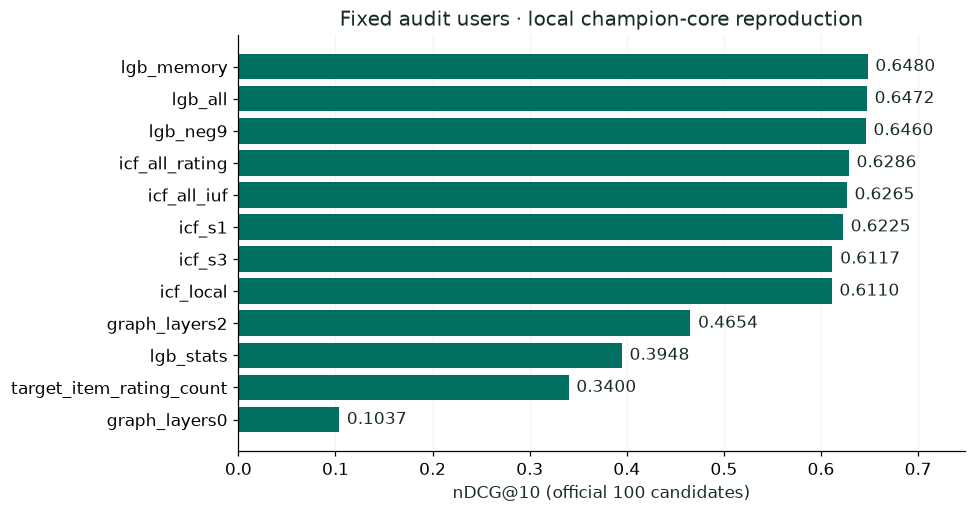

In [3]:
metrics = pd.read_csv(run / "metrics.csv")
table = metrics[(metrics.partition == "audit") & (metrics.market == "combined")].copy()
display(table[["model", "users", "ndcg10", "hr10"]].sort_values("ndcg10", ascending=False))
bar_scores(table, "Fixed audit users · local champion-core reproduction")

## 步骤 3 · 给提升一个可检查的尺度
对同一用户的分数差，按市场分层 bootstrap。区间反映这批用户抽样的不确定性，不能补偿反复看 audit 的选型偏差。
这里比较的模型在 selection.json 中已冻结。

In [4]:
from reclab.competition.teaching import paired_bootstrap
interval = paired_bootstrap(rows.loc[audit], predictions.loc[audit, "icf_local"], predictions.loc[audit, chosen])
display(interval)

{'users': 1605,
 'delta_b_minus_a': 0.037004412984351524,
 'bootstrap_95_interval': [0.027052149858014626, 0.046701845992888215],
 'scope': 'fixed published audit users; descriptive after repeated inspection'}

## 步骤 4 · 失败用户是什么样
查看正例名次靠后的用户和它们的已知历史长度。错误案例用于形成下一次假设，不能据此直接改答案。
例如：冷门商品缺少共现边、源市场口味不匹配、图模型训练不足。

In [5]:
errors = per_user(rows.loc[audit], predictions.loc[audit, chosen])
target_counts = rows[["market", "userId"]].join(features[["target_user_rating_count"]]).drop_duplicates(["market", "userId"])
errors = errors.merge(target_counts, on=["market", "userId"], validate="one_to_one")
display(errors.sort_values("rank", ascending=False).head(10))
bins = pd.cut(errors.target_user_rating_count, bins=[-1,2,5,10,np.inf], labels=["0-2", "3-5", "6-10", "11+"])
display(errors.assign(history_band=bins).groupby(["market", "history_band"], observed=True).agg(users=("userId","size"), ndcg10=("ndcg10","mean")))

,market,userId,rank,ndcg10,hr10,target_user_rating_count
688,t2,t2U1002369,100,0.0,0.0,6.0
903,t2,t2U1006445,99,0.0,0.0,6.0
1295,t2,t2U1013942,98,0.0,0.0,10.0
1398,t2,t2U1015657,96,0.0,0.0,6.0
661,t2,t2U1002049,95,0.0,0.0,7.0
1107,t2,t2U1010355,95,0.0,0.0,9.0
640,t2,t2U1001803,93,0.0,0.0,10.0
830,t2,t2U1005041,92,0.0,0.0,6.0
227,t1,t1U1004477,92,0.0,0.0,10.0
1462,t2,t2U1016591,91,0.0,0.0,7.0


users    ndcg10
market history_band                 
t1     0-2              42  0.920754
       3-5             126  0.779186
       6-10            289  0.694936
       11+              86  0.562768
t2     0-2              58  0.988506
       3-5             213  0.697184
       6-10            586  0.593280
       11+             205  0.489908

## 检查 · 这轮复现了什么
- **直接对照通过**：原版 ItemCF 评分公式，原版 LightGCN 的传播/BPR/梯度；完整官方数据、100 候选与 nDCG@10。
- **本机缩小或调整**：图模型维度/深度/训练更新数、特征数；用户隔离 fit/select/audit 替代原 10 折行级 bagging；不把另一目标市场 qrel 加进特征图。
- **没有复现**：完整 Word2Vec/Node2Vec/NCF/Swing/LLR/BiGraph 多组合集成、null importance 大规模筛选、最终隐藏测试成绩。原源码保留供回查。

## 下一步 · 自己做一次完整实验
建议先从 14 去掉一个市场特征，只看 select 成绩；再从 13 改采样或层数。
改模型实现后需要重训；修改的图模型要接入主流程时运行下面命令，会创建新 run，不覆盖旧产物。

In [6]:
print("cd", ROOT)
print(".venv/bin/python -m reclab.competition run --tag my-first-ablation --dim 32 --layers 2 --epochs 12")
print("当前 run 的配置:", run / "config.json")
print("指标:", run / "metrics.csv")
print("隐藏测试预测（无公开答案，不报分）:", run / f"test_{chosen}.parquet")

cd /Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab
.venv/bin/python -m reclab.competition run --tag my-first-ablation --dim 32 --layers 2 --epochs 12
当前 run 的配置: /Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/artifacts/xmrec/20261030T115556803593-cloud-restore/config.json
指标: /Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/artifacts/xmrec/20261030T115556803593-cloud-restore/metrics.csv
隐藏测试预测（无公开答案，不报分）: /Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/artifacts/xmrec/20261030T115556803593-cloud-restore/test_lgb_memory.parquet
